# Fall Binary Classifier v2 — Isolation Forest (Anomaly Detection)

**Binary:** FALL (anomaly) · NORMAL

**Why anomaly detection?**
SisFall binary files are z-score normalised per-window — incompatible with raw glove m/s².
Instead, we train ONLY on normal_hand_data.csv (glove normal motion).
The model learns exactly what your glove's normal motion looks like.
Any significant deviation (fall, impact, slam) is flagged as anomaly = FALL.

- **Normal data:** normal_hand_data.csv (87k rows, real glove motion)
- **Model:** Isolation Forest (unsupervised, no fall data needed)
- **Features:** 7 stats from accel magnitude per 2-second window
- Old notebook 01_fall_detection_train.ipynb is **not touched**

In [27]:
# Cell 1 - Config
import os, json, pickle
import numpy as np
import pandas as pd

NORMAL_PATH = '../data/normal_hand_data.csv'
MODELS_DIR  = '../models/'
os.makedirs(MODELS_DIR, exist_ok=True)

WIN    = 100    # 2 s at 50 Hz
STRIDE = 50     # 50% overlap for windowing
G      = 9.81   # g -> m/s2 conversion

# Isolation Forest: expected fraction of anomalies in NORMAL data
# 5% accounts for occasional fast hand movements during recording
CONTAMINATION = 0.05

FEATURE_NAMES = ['mean_mag','std_mag','min_mag','max_mag','range_mag','ac_energy_mag','zcr_mag']

print(f'CWD                : {os.getcwd()}')
print(f'NORMAL_PATH exists : {os.path.isfile(NORMAL_PATH)}')
print(f'Features           : {len(FEATURE_NAMES)}')

CWD                : c:\Users\asaad\OneDrive\Desktop\last try\neuropath_notebooks\neuropath\notebooks
NORMAL_PATH exists : True
Features           : 7


In [28]:
# Cell 2 - Load normal data, convert g->m/s2, compute magnitude
df_normal = pd.read_csv(NORMAL_PATH, usecols=['xAcc','yAcc','zAcc']).dropna()
df_normal[['xAcc','yAcc','zAcc']] *= G   # g -> m/s2
normal_mag = np.linalg.norm(df_normal.values, axis=1)
print(f'Normal rows        : {len(normal_mag):,}')
print(f'Normal magnitude   : mean={normal_mag.mean():.2f}  std={normal_mag.std():.2f}  '
      f'min={normal_mag.min():.2f}  max={normal_mag.max():.2f} m/s2')
print('At rest ~9.8 m/s2 = 1g gravity')

Normal rows        : 87,798
Normal magnitude   : mean=9.72  std=1.50  min=1.34  max=27.95 m/s2
At rest ~9.8 m/s2 = 1g gravity


In [29]:
# Cell 3 - Feature extraction (7 stats from magnitude)
def extract_7(win_1d):
    s  = np.asarray(win_1d, dtype=np.float64)
    sc = s - s.mean()   # AC component
    zcr = np.sum(np.diff(np.sign(sc)) != 0) / len(s)
    return np.array([
        s.mean(), s.std(), s.min(), s.max(),
        s.max() - s.min(),
        float(np.sum(sc**2)),   # AC energy (dynamic motion)
        zcr
    ], dtype=np.float64)

print(f'extract_7 shape: {extract_7(np.random.randn(100) + 9.8).shape}')
print('Feature extraction ready.')

extract_7 shape: (7,)
Feature extraction ready.


In [30]:
# Cell 4 - Window normal magnitude (time-based 80/20 split)
all_wins = [normal_mag[i:i+WIN] for i in range(0, len(normal_mag)-WIN+1, STRIDE)]
split = int(len(all_wins) * 0.80)
train_wins = all_wins[:split]   # fit Isolation Forest on this
test_wins  = all_wins[split:]   # held-out for threshold tuning
print(f'Normal windows - train: {len(train_wins)}  test: {len(test_wins)}')

Normal windows - train: 1403  test: 351


In [31]:
# Cell 5 - Extract features from training windows
print('Extracting features from normal training windows...')
X_train = np.array([extract_7(w) for w in train_wins])
X_test  = np.array([extract_7(w) for w in test_wins])
print(f'Train: {X_train.shape}  Test: {X_test.shape}')
print('\nFeature means (should all be from normal wrist motion):')
for name, val in zip(FEATURE_NAMES, X_train.mean(axis=0)):
    print(f'  {name:20s}: {val:.4f}')

Extracting features from normal training windows...
Train: (1403, 7)  Test: (351, 7)

Feature means (should all be from normal wrist motion):
  mean_mag            : 9.6248
  std_mag             : 1.0854
  min_mag             : 7.2161
  max_mag             : 13.1810
  range_mag           : 5.9649
  ac_energy_mag       : 218.3687
  zcr_mag             : 0.2435


In [32]:
# Cell 6 - Scale + Train Isolation Forest
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f'Training Isolation Forest (contamination={CONTAMINATION})...')
iso = IsolationForest(
    n_estimators=500,
    contamination=CONTAMINATION,
    random_state=42,
    n_jobs=-1
)
iso.fit(X_train_s)
print('Training complete.')

# Check: what fraction of normal test windows are flagged as anomaly?
# Isolation Forest returns +1=normal, -1=anomaly
test_preds = iso.predict(X_test_s)
anomaly_rate = (test_preds == -1).mean()
print(f'\nNormal test windows flagged as anomaly: {anomaly_rate*100:.1f}%')
print('(Expected ~5% from CONTAMINATION setting)')

Training Isolation Forest (contamination=0.05)...
Training complete.

Normal test windows flagged as anomaly: 5.7%
(Expected ~5% from CONTAMINATION setting)


Normal train score range: -0.1659 to 0.1336
Normal test  score range: -0.0270 to 0.1031
Anomaly threshold (5th pctile): -0.0000
Normal test flagged as FALL  : 5.7%


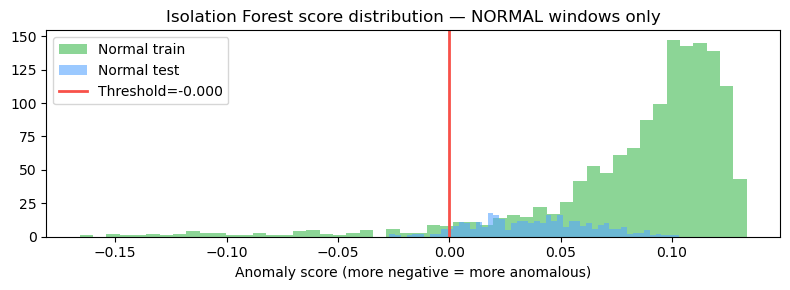

Score below threshold -> FALL alert


In [33]:
# Cell 7 - Threshold analysis using anomaly score
# The anomaly score < threshold means FALL. We use the decision_function output.
# More negative = more anomalous. We pick threshold at 95th percentile of NORMAL scores.

train_scores = iso.decision_function(X_train_s)
test_scores  = iso.decision_function(X_test_s)

# Threshold: 5th percentile of normal training scores
# Scores below this are anomalies (falls)
THRESHOLD = float(np.percentile(train_scores, 5))
print(f'Normal train score range: {train_scores.min():.4f} to {train_scores.max():.4f}')
print(f'Normal test  score range: {test_scores.min():.4f} to {test_scores.max():.4f}')
print(f'Anomaly threshold (5th pctile): {THRESHOLD:.4f}')
print(f'Normal test flagged as FALL  : {(test_scores < THRESHOLD).mean()*100:.1f}%')

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(train_scores, bins=50, alpha=0.6, label='Normal train', color='#3fb950')
ax.hist(test_scores,  bins=50, alpha=0.6, label='Normal test',  color='#58a6ff')
ax.axvline(THRESHOLD, color='#f85149', linewidth=2, label=f'Threshold={THRESHOLD:.3f}')
ax.set_xlabel('Anomaly score (more negative = more anomalous)')
ax.set_title('Isolation Forest score distribution — NORMAL windows only')
ax.legend()
plt.tight_layout()
plt.savefig(MODELS_DIR+'fall_binary_evaluation.png', dpi=120, bbox_inches='tight')
plt.show()
print('Score below threshold -> FALL alert')

In [34]:
# Cell 8 - Save model files
with open(MODELS_DIR+'fall_binary_classifier.pkl', 'wb') as f: pickle.dump(iso, f)
with open(MODELS_DIR+'fall_binary_scaler.pkl',     'wb') as f: pickle.dump(scaler, f)

config = {
    'model_type'      : 'IsolationForest',
    'classes'         : ['normal', 'fall'],
    'feature_names'   : FEATURE_NAMES,
    'window_size'     : WIN,
    'stride'          : STRIDE,
    'sampling_hz'     : 50,
    'threshold'       : THRESHOLD,
    'contamination'   : CONTAMINATION,
    'normal_false_positive_rate': float((test_scores < THRESHOLD).mean()),
    'note': 'IsoForest trained on glove normal data only; score < threshold = FALL'
}
with open(MODELS_DIR+'fall_binary_model_config.json', 'w') as f:
    json.dump(config, f, indent=2)

for fname in ['fall_binary_classifier.pkl','fall_binary_scaler.pkl',
              'fall_binary_model_config.json','fall_binary_evaluation.png']:
    size = os.path.getsize(MODELS_DIR+fname)/1024
    print(f'  {fname:40s} {size:7.1f} KB')
print(f'\nThreshold     : {THRESHOLD:.4f}')
print(f'False positive: {config["normal_false_positive_rate"]*100:.1f}% on held-out normal data')
print('Model ready. Score < threshold -> FALL. Test by slamming the glove on a table.')

  fall_binary_classifier.pkl                6241.7 KB
  fall_binary_scaler.pkl                       0.6 KB
  fall_binary_model_config.json                0.5 KB
  fall_binary_evaluation.png                  30.7 KB

Threshold     : -0.0000
False positive: 5.7% on held-out normal data
Model ready. Score < threshold -> FALL. Test by slamming the glove on a table.
